**[🏠 Course Home](00_START_HERE.ipynb)** | **📖 [Conceptual](../conceptual/19_verifying_flaky_test_fixes.ipynb)** | **🐍 [Python](../python/19_verifying_flaky_test_fixes.ipynb)** | **⬅️ [Prev: Ch 18: Flaky Tests & Pipeline Synthesis](18_case_studies_flaky_tests_and_pipelines.ipynb)** | **➡️ [Next: Ch 20: CI/CD Test Promotion Gatekeeping](20_test_promotion_heuristics_vs_bayes.ipynb)**

*🧭 Part V: Production Reliability, CI/CD & Active Learning — Chapter 19 of 22*

---

# Chapter 19: Verifying Flaky Test Fixes in R
## Frequentist vs. Bayesian Approaches
### *Why 0/100 Passes Proves Almost Nothing, and How Wald's SPRT,
Bayes Factors, and Sequential Stopping Solve CI Flakiness in Base R*

---

> 📖 **Conceptual Companion**: The 50-sided die, the courtroom shoe print
> ($BF=4.0$), and the hydraulic shake table:
> Read **[Chapter 19: The 50-Sided Die & Sequential Stopping](../conceptual/19_verifying_flaky_test_fixes.ipynb)**.

---

## 1. Problem Framing: The Software Engineering Dilemma

Every software engineer, DevOps engineer, and infrastructure lead has lived
through this exact scenario:

```text
Step 1: In CI, an automated integration test begins failing intermittently.
        Across the last 100 runs on main, it failed twice:
        Pre-fix failure rate: 2 failures / 100 runs = 2.0%

Step 2: An engineer investigates, spots a likely race condition or timeout,
        writes a patch, and opens a Pull Request (PR).

Step 3: To "prove" the fix works, they loop the test 100 times locally or in CI:
        for i in {1..100}; do pytest tests/test_payment.py; done

Step 4: All 100 runs pass without a single failure (0/100)!

Step 5: The engineer posts a PR comment: "Fixed! Passed 100/100 runs."
        The PR is approved and merged to main...
        ...and 48 hours later, the exact same test flakes during deployment!
```

---

### 🎲 The Everyday Intuition: The 50-Sided Die

Why does this happen so frequently? Consider this simple physical game:

> [!IMPORTANT]
> **The 50-Sided Die (The Loaded Die Mental Model)**
>
> Imagine someone hands you a **50-sided die** where exactly **one face** is
> painted bright red (representing the 2% failure rate).
>
> * If you roll this die **100 times**, what is the probability that the red
>   face **never shows up at all**?
> * Each roll has a $49/50 = 98\%$ chance of landing safe.
> * The probability of rolling 100 safe faces in a row is:
>   $$P(0 \text{ red in } 100) = (0.98)^{100} \approx 0.1326 \quad (13.3\%)$$
>
> **Think about what 13.3% means in everyday life:**
> * When you roll a standard **6-sided board game die**, your chance of rolling
>   a **6** on a single roll is $1/6 \approx 16.7\%$.
> * A $13.3\%$ probability is roughly **1 out of every 7.5 times**!
> * If you roll a 6 on a single die roll, you do not declare that the die is
>   broken. Yet engineers celebrate 100 passes as "irrefutable proof"
>   when they merely observed an outcome **almost as common as rolling a 6 on a
>   die**!

---

### 🧠 The Human Intuition Trap: The Illusion of "100"

Why do smart engineers consistently fall for this trap?
* **The Cognitive Bias**: Human intuition evolved to count visible objects.
  To our brains, the number **100** feels enormous, exhaustive, and conclusive.
* **The Statistical Reality**: In probability theory, **sample size has no
  absolute meaning in isolation**. Sample size only has meaning **relative to
  the rarity of the event** you are trying to detect!
  * If a system fails $10\%$ of the time, 100 runs is plenty of evidence.
  * If a satellite fails once per $1{,}000{,}000$ hours, 100 hours proves
    nothing.
  * For a test that flakes $2\%$ of the time, 100 runs is a tiny peephole!

---

### 🗺️ What This Guide Teaches You

This notebook deconstructs this problem through both foundational statistical
lenses and provides practical production solutions:

| Statistical Question | Frequentist Lens (Sections 2.1 – 2.4) | Bayesian Lens (Sections 3.1 – 3.3) | Practical CI Production Solution |
| :--- | :--- | :--- | :--- |
| **Did the test improve?** | **Fisher's Exact Test**: $p = 0.25$ (Fails significance test). | **Bayes Factor**: $BF_{10} = 4.0$ (Weak circumstantial evidence). | Do not promote or merge on 100 clean runs alone. |
| **Guaranteed failure rate?** | **Rule of Three**: True flakiness is upper-bounded by $\le 3.0\%$. | **Beta Posterior**: Full credible interval $[0.0\%, 2.9\%]$. | If using fixed batches, compute $N \ge 3 / p_{\text{tolerance}}$ ($300\text{--}600$ runs). |
| **Avoid wasting CI compute?** | **Wald's SPRT**: Dynamic sequential stopping stops early. | **Posterior Updating**: Online belief updating after every individual run. | Abort immediately on the first failure post-fix. |
| **Incorporate PR quality?** | ❌ Cannot incorporate prior context (pure data only). | ✅ **Prior Odds**: Weights evidence by fix archetype ($35\%$ vs $95\%$). | Use Bayesian decision gates based on change risk archetype. |
| **When is it optimal to stop?** | Arbitrary $\alpha$ and $\beta$ thresholds. | **Bayesian Decision Theory**: Balances \$0.01 runner cost vs \$500 broken-build cost. | Stop when the cost of testing exceeds expected failure risk. |

In [1]:
# Set reproducible seed and clean console formatting
set.seed(42)
options(scipen = 7, digits = 5)

# Verify Base R stats and graphics capabilities
cat("Base R statistical and graphics environment initialized.\n")

Base R statistical and graphics environment initialized.


---

## 2. The Frequentist Deconstruction

Let us begin by applying classical frequentist hypothesis testing to the
engineer's experiment.

### 2.1 The Two-Proportion Test & Fisher's Exact Test

In the frequentist framework, we set up two competing hypotheses about the
true pre-fix failure probability $p_{\text{pre}}$ and the post-fix failure
probability $p_{\text{post}}$:
* **Null Hypothesis ($H_0$)**: The fix did nothing: $p_{\text{post}} = p_{\text{pre}} = 0.02$.
* **Alternative Hypothesis ($H_1$)**: The fix improved the test: $p_{\text{post}} < p_{\text{pre}}$.

We construct the $2 \times 2$ contingency table of observed outcomes:
* Pre-fix: 2 failures, 98 passes ($N = 100$)
* Post-fix: 0 failures, 100 passes ($N = 100$)

Because the failure counts are small ($< 5$), asymptotic Chi-square tests are
invalid. We compute the exact hypergeometric probability using
**Fisher's Exact Test** (`fisher.test` in R).

In [2]:
# 2x2 contingency table: rows = [Pre, Post], columns = [Fail, Pass]
contingency_table <- matrix(
  c(2, 98,
    0, 100),
  nrow = 2, byrow = TRUE,
  dimnames = list(Stage = c("Pre-Fix", "Post-Fix"),
                  Result = c("Fail", "Pass"))
)

print(contingency_table)

# One-sided Fisher's Exact Test: alternative = "greater" tests if
# the odds of failure pre-fix are greater than post-fix
fisher_res <- fisher.test(contingency_table, alternative = "greater")

cat("\n=======================================================\n")
cat("FISHER'S EXACT TEST FOR FLAKY TEST FIX VERIFICATION\n")
cat("=======================================================\n")
cat(sprintf("p-value:                  %.4f\n", fisher_res$p.value))
cat(sprintf("Statistically Significant (alpha = 0.05): %s\n",
            ifelse(fisher_res$p.value < 0.05, "YES", "NO")))
cat("=======================================================\n")

          Result
Stage      Fail Pass
  Pre-Fix     2   98
  Post-Fix    0  100


FISHER'S EXACT TEST FOR FLAKY TEST FIX VERIFICATION


p-value:                  0.2487


Statistically Significant (alpha = 0.05): NO


---

> [!WARNING]
> ### ⚖️ The Frequentist Verdict: Inconclusive ($p \approx 0.25$)
>
> Under classical frequentist null-hypothesis significance testing (NHST), the
> resulting $p$-value is **$p = 0.2487$** (roughly $25\%$).
>
> What does $p = 0.25$ mean?
> * If the developer's PR **did absolutely nothing** (the true failure rate
>   remained $2\%$), there is a **$25\%$ probability** of observing a
>   difference this large or larger purely by random sampling noise!
> * Because $p = 0.25 > 0.05$, a frequentist statistician **fails to reject the
>   null hypothesis**.
> * From a classical testing perspective, **100 clean runs provides zero
>   statistically significant evidence that the bug was fixed**!

### 2.3 The Rule of Three & Upper Confidence Bounds

When you run a test $N$ times and observe **zero failures** ($k = 0$), what is
the frequentist $95\%$ upper confidence bound on the true failure rate $p$?

In classical statistics, this is governed by the **Rule of Three** (Jovanovic
& Levy, 1997; Louis, 1981):
$$\hat{p}_{95\% \text{ Upper}} \approx \frac{3}{N}$$

For $N = 100$ runs with $0$ failures:
$$\hat{p}_{95\% \text{ Upper}} \approx \frac{3}{100} = 3.0\%$$

The exact **Clopper-Pearson** binomial confidence interval yields:
$$1 - (0.05)^{1/N} = 1 - 0.05^{0.01} \approx 2.951\%$$

> **The Bitter Irony**: After running 100 consecutive clean passes, your $95\%$
> upper confidence bound is **$3.0\%$**—which is **higher than the original
> $2.0\%$ failure rate** you set out to fix! To mathematically bound the
> post-fix failure rate below $0.5\%$, you would need at least
> $N = 3 / 0.005 = 600$ clean runs.

In [3]:
# Exact Clopper-Pearson 95% Upper Bound for k = 0 failures in N runs
clopper_pearson_upper_bound <- function(n, alpha = 0.05) {
  1.0 - alpha^(1.0 / n)
}

sample_sizes <- c(20, 50, 100, 200, 500, 1000)
cat(sprintf("%-15s | %-20s | %-20s\n", "Runs (N)", "Rule of Three (3/N)", "Exact Clopper-Pearson"))
cat(paste(rep("-", 62), collapse = ""), "\n")

for (n in sample_sizes) {
  r3 <- 3.0 / n
  cp <- clopper_pearson_upper_bound(n, alpha = 0.05)
  cat(sprintf("%-15d | %6.2f%%              | %6.2f%%\n", n, r3 * 100, cp * 100))
}

Runs (N)        | Rule of Three (3/N)  | Exact Clopper-Pearson


-------------------------------------------------------------- 


20              |  15.00%              |  13.91%
50              |   6.00%              |   5.82%
100             |   3.00%              |   2.95%
200             |   1.50%              |   1.49%
500             |   0.60%              |   0.60%
1000            |   0.30%              |   0.30%


---

### 2.4 Frequentist Solution: Wald's Sequential Test (SPRT)

Fixed-sample testing ($N = 100$) forces engineers into a double trap:
1. If the fix failed, running 100 tests wastes CI compute when the test fails
   on run 8.
2. If the fix succeeded, 100 tests is insufficient to prove health.

The classical solution developed by Abraham Wald (1945) is **Sequential
Analysis (SPRT)**. Instead of fixing $N$ beforehand, tests are evaluated after
every individual run $m$.

We test:
* $H_0$: Clean test ($p_0 = 0.001$, 1 in 1,000)
* $H_1$: Flaky test ($p_1 = 0.020$, 1 in 50)

With Type I error $\alpha = 0.05$ and Type II error $\beta = 0.05$, Wald's log
decision boundaries are:
$$A = \ln\left(\frac{1 - \beta}{\alpha}\right) = \ln\left(\frac{0.95}{0.05}\right) = +2.944$$
$$B = \ln\left(\frac{\beta}{1 - \alpha}\right) = \ln\left(\frac{0.05}{0.95}\right) = -2.944$$

The cumulative log-likelihood ratio $S_m = \sum_{i=1}^m z_i$ updates by:
* On a **PASS**: $z_{\text{pass}} = \ln\left(\frac{1 - p_1}{1 - p_0}\right) = \ln\left(\frac{0.980}{0.999}\right) = -0.0192$
* On a **FAIL**: $z_{\text{fail}} = \ln\left(\frac{p_1}{p_0}\right) = \ln\left(\frac{0.020}{0.001}\right) = +2.996$

Notice the dramatic asymmetry: **a single failure adds $+2.996$**, instantly
crossing boundary $A$ and aborting the run!

In [4]:
# Wald's Sequential Probability Ratio Test (SPRT) Engine in Base R
create_sprt_engine <- function(p0 = 0.001, p1 = 0.02, alpha = 0.05, beta = 0.05) {
  A_bound <- log((1 - beta) / alpha)
  B_bound <- log(beta / (1 - alpha))
  ll_fail <- log(p1 / p0)
  ll_pass <- log((1 - p1) / (1 - p0))
  
  runs_needed_clean <- ceiling(B_bound / ll_pass)
  
  list(
    p0 = p0, p1 = p1, alpha = alpha, beta = beta,
    A = A_bound, B = B_bound,
    ll_fail = ll_fail, ll_pass = ll_pass,
    runs_needed_clean = runs_needed_clean
  )
}

sprt <- create_sprt_engine(p0 = 0.001, p1 = 0.02, alpha = 0.05, beta = 0.05)

cat(sprintf("SPRT Upper Boundary A (Reject H0 -> Flaky): %+.3f\n", sprt$A))
cat(sprintf("SPRT Lower Boundary B (Accept H0 -> Clean): %+.3f\n", sprt$B))
cat(sprintf("Single failure log-weight increment:        %+.3f\n", sprt$ll_fail))
cat(sprintf("Single pass log-weight increment:           %+.3f\n", sprt$ll_pass))
cat(sprintf("Consecutive clean passes needed to certify: %d runs\n", sprt$runs_needed_clean))

SPRT Upper Boundary A (Reject H0 -> Flaky): +2.944


SPRT Lower Boundary B (Accept H0 -> Clean): -2.944


Single failure log-weight increment:        +2.996


Single pass log-weight increment:           -0.019


Consecutive clean passes needed to certify: 154 runs


---

## 3. The Bayesian Deconstruction

Frequentist testing asks: *"Assuming the fix did nothing, how improbable is
our data?"*
Bayesian testing asks the question engineers actually care about:
> *"Given that the test just passed 100 times in a row, what is the probability
> that the fix actually worked?"*

### 3.1 Model Comparison & The Bayes Factor ($BF_{10}$)

We specify two concrete competing models:
* **Model 0 ($M_0$: Fix Failed)**: The bug is still present. Based on historical
  pre-fix telemetry (2 fails in 100 runs), the failure rate is parameterized by
  $\theta \sim \text{Beta}(\alpha=3, \beta=99)$ with mean $2.9\%$.
* **Model 1 ($M_1$: Fix Succeeded)**: The bug was resolved. The test now operates
  at clean baseline reliability, parameterized by
  $\theta \sim \text{Beta}(\alpha=1, \beta=100)$ with mean $1.0\%$.

To compare these models given new post-fix data $D = (k=0 \text{ failures in } n=100 \text{ runs})$,
we evaluate their **marginal likelihoods** using Euler's Beta-Binomial integral:
$$P(D \mid M) = \int_0^1 \binom{n}{k} \theta^k (1 - \theta)^{n - k} \cdot \frac{\theta^{\alpha-1} (1-\theta)^{\beta-1}}{B(\alpha, \beta)} \, d\theta = \binom{n}{k} \frac{B(k + \alpha, n - k + \beta)}{B(\alpha, \beta)}$$

In log-space, this is evaluated in Base R via `lchoose()` and `lbeta()`:
$$\ln P(D \mid M) = \text{lchoose}(n, k) + \text{lbeta}(k + \alpha, n - k + \beta) - \text{lbeta}(\alpha, \beta)$$

In [5]:
# Analytical marginal log-likelihood under Beta-Binomial conjugacy
beta_bin_lpmf <- function(k, n, a, b) {
  lchoose(n, k) + lbeta(k + a, n - k + b) - lbeta(a, b)
}

log_lik_M0 <- beta_bin_lpmf(k = 0, n = 100, a = 3, b = 99)
log_lik_M1 <- beta_bin_lpmf(k = 0, n = 100, a = 1, b = 100)

lik_M0 <- exp(log_lik_M0)
lik_M1 <- exp(log_lik_M1)
bayes_factor <- lik_M1 / lik_M0

cat("=================================================================\n")
cat("BAYESIAN MODEL COMPARISON: 100 PASSES POST-FIX\n")
cat("=================================================================\n")
cat(sprintf("P(100 passes | M0: Fix Failed)  = %.4f (%.1f%%)\n", lik_M0, lik_M0 * 100))
cat(sprintf("P(100 passes | M1: Fix Worked)  = %.4f (%.1f%%)\n", lik_M1, lik_M1 * 100))
cat(sprintf("Bayes Factor (BF_10)            = %.2f\n", bayes_factor))
cat("=================================================================\n")
cat("Harold Jeffreys Evidence Scale:\n")
cat("  BF 1 - 3:   Anecdotal / Barely worth mentioning\n")
cat("  BF 3 - 10:  Substantial / Moderate (CURRENT RESULT: 4.00)\n")
cat("  BF 10 - 30: Strong\n")
cat("  BF > 100:   Decisive\n")
cat("=================================================================\n")

BAYESIAN MODEL COMPARISON: 100 PASSES POST-FIX


P(100 passes | M0: Fix Failed)  = 0.1250 (12.5%)


P(100 passes | M1: Fix Worked)  = 0.5000 (50.0%)


Bayes Factor (BF_10)            = 4.00


Harold Jeffreys Evidence Scale:


  BF 1 - 3:   Anecdotal / Barely worth mentioning


  BF 3 - 10:  Substantial / Moderate (CURRENT RESULT: 4.00)


  BF 10 - 30: Strong


  BF > 100:   Decisive


### 3.3 Prior Fix Efficacy: Not All PRs Are Created Equal

Frequentist statistics suffers from **structural amnesia**: it forces every PR
to be evaluated as an isolated slate, ignoring engineering context.

In production engineering, the prior probability of fix success varies
dramatically across PR archetypes:
1. **Low-Confidence Heuristic ($P(\text{Fix}) = 0.35$)**: The author bumped an
   arbitrary `sleep(1)` to `sleep(5)` or added a speculative retry loop.
2. **Standard Team PR ($P(\text{Fix}) = 0.70$)**: Standard refactor with unit
   tests and peer review.
3. **High-Confidence Root-Cause Fix ($P(\text{Fix}) = 0.95$)**: Deterministic
   lock ordering fix or missing mock barrier identified in dump analysis.

Using Bayes' theorem in odds form:
$$\text{Posterior Odds} = \text{Prior Odds} \times \text{Bayes Factor}$$
$$O(M_1 \mid D) = O(M_1) \times BF_{10}$$
$$P(M_1 \mid D) = \frac{O(M_1 \mid D)}{1 + O(M_1 \mid D)}$$

In [6]:
priors <- c(0.35, 0.70, 0.95)
labels <- c("Heuristic ('Bumped Sleep')", "Standard Team PR", "Root-Cause Code Fix")

cat("IMPACT OF PRIOR FIX QUALITY AFTER 100 CLEAN PASSES (BF = 4.00):\n")
cat(sprintf("%-28s | %-12s | %-14s | %s\n", "PR Fix Archetype", "Prior P(Fix)", "Prior Odds", "Posterior P(Fix)"))
cat(paste(rep("-", 75), collapse = ""), "\n")

for (i in seq_along(priors)) {
  p_prior <- priors[i]
  prior_odds <- p_prior / (1 - p_prior)
  post_odds <- prior_odds * bayes_factor
  p_post <- post_odds / (1 + post_odds)
  cat(sprintf("%-28s | %5.1f%%       | %6.2f:1        | %5.1f%%\n",
              labels[i], p_prior * 100, prior_odds, p_post * 100))
}

IMPACT OF PRIOR FIX QUALITY AFTER 100 CLEAN PASSES (BF = 4.00):


PR Fix Archetype             | Prior P(Fix) | Prior Odds     | Posterior P(Fix)


--------------------------------------------------------------------------- 


Heuristic ('Bumped Sleep')   |  35.0%       |   0.54:1        |  68.3%
Standard Team PR             |  70.0%       |   2.33:1        |  90.3%
Root-Cause Code Fix          |  95.0%       |  19.00:1        |  98.7%


---

> [!IMPORTANT]
> ### 🏺 The Key Bayesian Insight: The Asymmetry of Evidence (The Porcelain Vase)
>
> Consider an expensive porcelain vase:
> * If you drop the vase on concrete and it **shatters into pieces**, you have
>   **100% decisive proof** that the vase is fragile. A single negative event
>   shatters the hypothesis of invulnerability.
> * If you pick up the vase and place it gently on the table **100 times without
>   breaking it**, have you proved that it is unbreakable? **Not at all.**
>
> In software testing, **failures carry immense information; passes carry very
> little**:
> * A single failure is informative: $\Delta S = +3.00$ in SPRT.
> * A single pass is nearly uninformative: $\Delta S = -0.019$ in SPRT.
>
> To compensate for this asymmetry, you need vast numbers of passes to prove
> health, but only **one** failure to prove ongoing flakiness!

---

## 4. Visualizing the Evidence: Frequentist vs. Bayesian Diagnostics

Let us generate high-resolution diagnostic panels in Base R illustrating:
1. **Diagnostic Dashboard 1**: Sampling distributions of failures ($N=100$) and
   the Zero-Failure sampling curve $(1-p)^N$ vs sample size $N$.
2. **Diagnostic Dashboard 2**: Sequential SPRT dynamic stopping trajectories vs
   Bayesian posterior probability curves under accumulating clean passes.

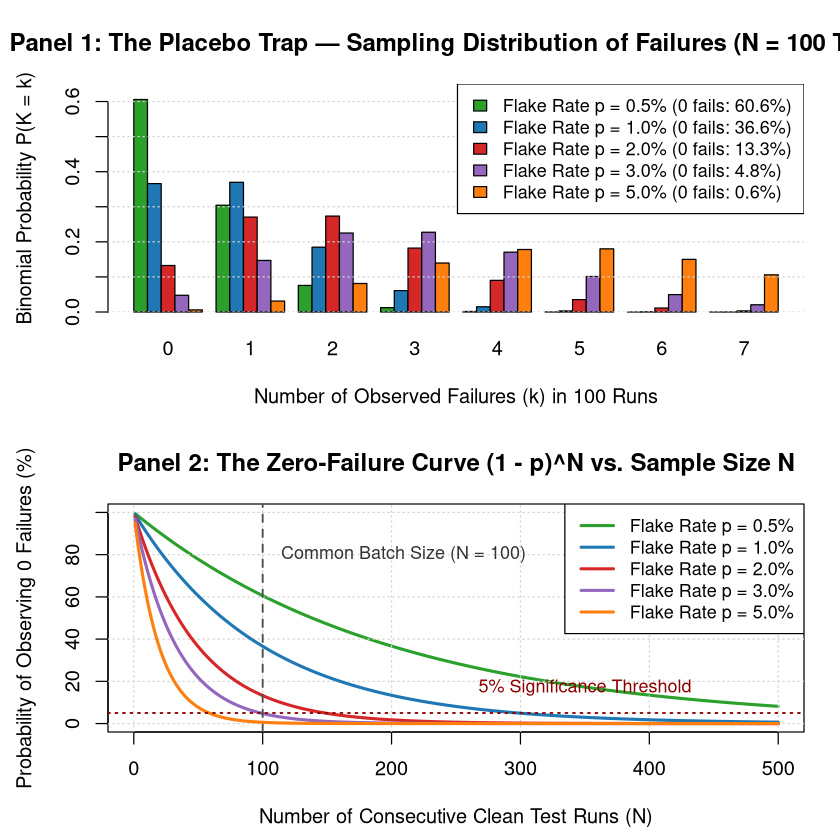

In [7]:
# Diagnostic Dashboard 1: Sampling Distribution & Zero-Failure Curve
par(mfrow = c(2, 1), mar = c(4.5, 4.5, 3.5, 1.5))

# -------------------------------------------------------------
# Panel 1: Binomial Sampling Distribution for N = 100 Runs
# -------------------------------------------------------------
k_vals <- 0:7
n_trials <- 100
flake_rates <- c(0.005, 0.01, 0.02, 0.03, 0.05)
colors <- c("#2ca02c", "#1f77b4", "#d62728", "#9467bd", "#ff7f0e")

pmf_mat <- matrix(NA, nrow = length(flake_rates), ncol = length(k_vals))
for (i in seq_along(flake_rates)) {
  pmf_mat[i, ] <- dbinom(k_vals, size = n_trials, prob = flake_rates[i])
}

bp <- barplot(pmf_mat, beside = TRUE, col = colors, names.arg = k_vals,
              xlab = "Number of Observed Failures (k) in 100 Runs",
              ylab = "Binomial Probability P(K = k)",
              ylim = c(0, 0.65),
              main = "Panel 1: The Placebo Trap — Sampling Distribution of Failures (N = 100 Trials)")
grid(nx = NA, ny = NULL)

legend("topright",
       legend = sprintf("Flake Rate p = %.1f%% (0 fails: %.1f%%)",
                        flake_rates * 100, pmf_mat[, 1] * 100),
       fill = colors, bg = "white", cex = 0.9)

# -------------------------------------------------------------
# Panel 2: The Zero-Failure Curve (1 - p)^N vs. Sample Size N
# -------------------------------------------------------------
N_seq <- 1:500
plot(N_seq, (1 - flake_rates[1])^N_seq * 100, type = "l", col = colors[1], lwd = 2.5,
     ylim = c(0, 100), xlim = c(0, 500),
     xlab = "Number of Consecutive Clean Test Runs (N)",
     ylab = "Probability of Observing 0 Failures (%)",
     main = "Panel 2: The Zero-Failure Curve (1 - p)^N vs. Sample Size N")
grid()

for (i in 2:length(flake_rates)) {
  lines(N_seq, (1 - flake_rates[i])^N_seq * 100, col = colors[i], lwd = 2.5)
}

abline(v = 100, col = "gray30", lty = 2, lwd = 1.5)
abline(h = 5, col = "darkred", lty = 3, lwd = 1.5)
text(105, 80, "Common Batch Size (N = 100)", pos = 4, col = "gray20", cex = 0.9)
text(350, 9, "5% Significance Threshold", pos = 3, col = "darkred", cex = 0.9)

legend("topright",
       legend = sprintf("Flake Rate p = %.1f%%", flake_rates * 100),
       col = colors, lty = 1, lwd = 2.5, bg = "white", cex = 0.9)

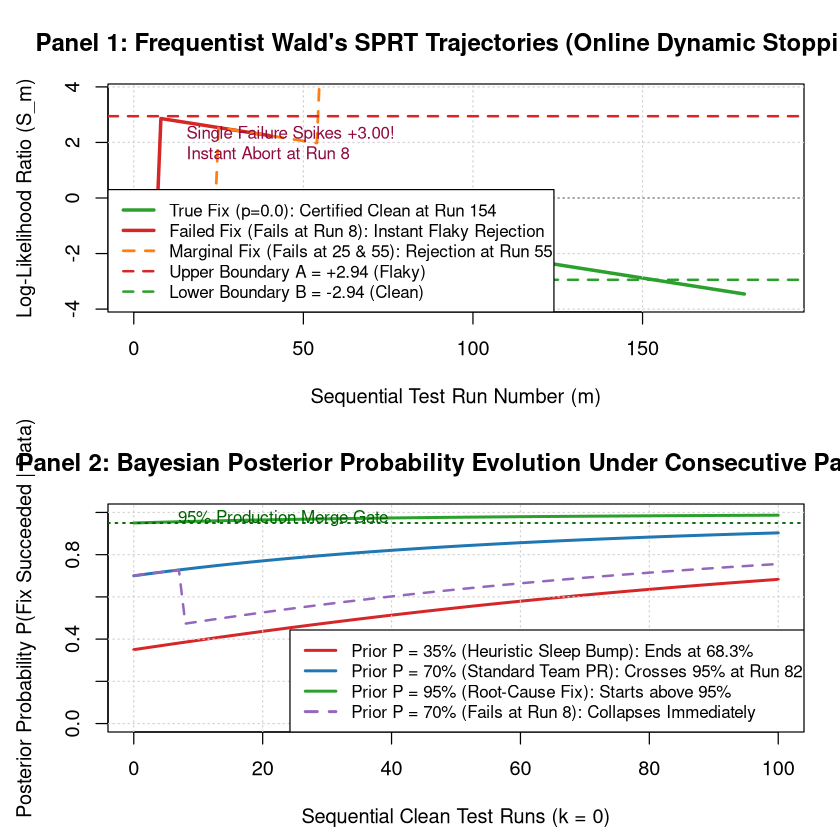

In [8]:
# Diagnostic Dashboard 2: SPRT Trajectories & Bayesian Posterior Evolution
par(mfrow = c(2, 1), mar = c(4.5, 4.5, 3.5, 1.5))

# -------------------------------------------------------------
# Panel 1: Wald's SPRT Sequential Log-Likelihood Ratio Trajectory
# -------------------------------------------------------------
p0 <- 0.001
p1 <- 0.02
alpha <- 0.05
beta <- 0.05

A_bound <- log((1 - beta) / alpha)
B_bound <- log(beta / (1 - alpha))
ll_fail <- log(p1 / p0)
ll_pass <- log((1 - p1) / (1 - p0))

# Trajectory A: True Fix (0 failures for 180 runs)
runs_A <- 180
scores_A <- c(0, cumsum(rep(ll_pass, runs_A)))

# Trajectory B: Failed Fix (fails at run 8)
runs_B <- 40
diffs_B <- rep(ll_pass, runs_B)
diffs_B[8] <- ll_fail
scores_B <- c(0, cumsum(diffs_B))

# Trajectory C: Marginal Fix (fails at run 25 and 55)
runs_C <- 70
diffs_C <- rep(ll_pass, runs_C)
diffs_C[c(25, 55)] <- ll_fail
scores_C <- c(0, cumsum(diffs_C))

plot(0:runs_A, scores_A, type = "l", col = "#2ca02c", lwd = 2.8,
     xlim = c(0, 190), ylim = c(-3.8, 3.8),
     xlab = "Sequential Test Run Number (m)",
     ylab = "Log-Likelihood Ratio (S_m)",
     main = "Panel 1: Frequentist Wald's SPRT Trajectories (Online Dynamic Stopping)")
grid()

lines(0:runs_B, scores_B, col = "#d62728", lwd = 2.8)
lines(0:runs_C, scores_C, col = "#ff7f0e", lwd = 2.2, lty = 2)

abline(h = A_bound, col = "#d62728", lty = 2, lwd = 2)
abline(h = B_bound, col = "#2ca02c", lty = 2, lwd = 2)
abline(h = 0, col = "gray50", lty = 3)

text(12, 1.8, "Single Failure Spikes +3.00!\nInstant Abort at Run 8", pos = 4, col = "#900C3F", cex = 0.85)

legend("bottomleft",
       legend = c("True Fix (p=0.0): Certified Clean at Run 154",
                  "Failed Fix (Fails at Run 8): Instant Flaky Rejection",
                  "Marginal Fix (Fails at 25 & 55): Rejection at Run 55",
                  sprintf("Upper Boundary A = +%.2f (Flaky)", A_bound),
                  sprintf("Lower Boundary B = %.2f (Clean)", B_bound)),
       col = c("#2ca02c", "#d62728", "#ff7f0e", "#d62728", "#2ca02c"),
       lty = c(1, 1, 2, 2, 2), lwd = c(2.8, 2.8, 2.2, 2, 2), bg = "white", cex = 0.85)

# -------------------------------------------------------------
# Panel 2: Bayesian Posterior Probability Evolution
# -------------------------------------------------------------
get_bayes_trajectory <- function(p_prior, fails = c()) {
  n_seq <- 0:100
  p_traj <- numeric(length(n_seq))
  p_traj[1] <- p_prior
  prior_odds <- p_prior / (1 - p_prior)
  
  k <- 0
  for (n in 1:100) {
    if (n %in% fails) k <- k + 1
    ll_1 <- beta_bin_lpmf(k, n, 1, 100)
    ll_0 <- beta_bin_lpmf(k, n, 3, 99)
    bf <- exp(ll_1 - ll_0)
    post_odds <- prior_odds * bf
    p_traj[n + 1] <- post_odds / (1 + post_odds)
  }
  p_traj
}

p_heur <- get_bayes_trajectory(0.35)
p_std  <- get_bayes_trajectory(0.70)
p_root <- get_bayes_trajectory(0.95)
p_fail <- get_bayes_trajectory(0.70, fails = 8)

plot(0:100, p_heur, type = "l", col = "#d62728", lwd = 2.4,
     ylim = c(0, 1.0), xlim = c(0, 100),
     xlab = "Sequential Clean Test Runs (k = 0)",
     ylab = "Posterior Probability P(Fix Succeeded | Data)",
     main = "Panel 2: Bayesian Posterior Probability Evolution Under Consecutive Passes")
grid()

lines(0:100, p_std, col = "#1f77b4", lwd = 2.4)
lines(0:100, p_root, col = "#2ca02c", lwd = 2.4)
lines(0:100, p_fail, col = "#9467bd", lwd = 2.0, lty = 2)

abline(h = 0.95, col = "darkgreen", lty = 3, lwd = 1.5)
text(5, 0.97, "95% Production Merge Gate", pos = 4, col = "darkgreen", cex = 0.85)

legend("bottomright",
       legend = c("Prior P = 35% (Heuristic Sleep Bump): Ends at 68.3%",
                  "Prior P = 70% (Standard Team PR): Crosses 95% at Run 82",
                  "Prior P = 95% (Root-Cause Fix): Starts above 95%",
                  "Prior P = 70% (Fails at Run 8): Collapses Immediately"),
       col = c("#d62728", "#1f77b4", "#2ca02c", "#9467bd"),
       lty = c(1, 1, 1, 2), lwd = 2.4, bg = "white", cex = 0.85)

---

## 5. Bayesian Decision Theory & The Production Playbook

### 5.1 The Asymmetric CI Cost Matrix

In continuous integration and deployment pipelines, errors carry radically
asymmetric business costs:
* **Cost of running 1 test ($C_{\text{run}}$)**: $\approx \$0.01$ (compute)
* **Cost of a False Pass ($C_{\text{false\_pass}}$)**: $\approx \$500$
  (A broken or flaky build merges to main, blocking dozens of developers).
* **Cost of a False Quarantine ($C_{\text{false\_quarantine}}$)**: $\approx \$50$
  (A valid test is quarantined, delaying developer feedback).

Under **Bayesian Decision Theory (Chapter 16)**, the optimal decision threshold
$P^*(\text{Clean})$ balances these costs:
$$P^*(\text{Clean}) = \frac{C_{\text{false\_pass}}}{C_{\text{false\_pass}} + C_{\text{false\_quarantine}}} = \frac{500}{500 + 50} \approx 90.9\%$$

### 5.2 The 4-Step Production Implementation Guide

1. **Abort on First Failure**:
   Never run fixed 100-test loops if a test fails early. A single failure is
   decisive evidence that the test remains flaky. Abort at run 1 or 8!
2. **Size Runs by Prior Archetype**:
   * Root-cause code fix ($P_0 = 95\%$): Needs only $20\text{--}30$ clean runs.
   * Standard PR ($P_0 = 70\%$): Needs $80\text{--}100$ clean runs.
   * Sleep bump heuristic ($P_0 = 35\%$): Needs $> 250$ clean runs.
3. **Use SPRT for High-Throughput Automation**:
   Implement dynamic stopping bounds ($A = +2.94$, $B = -2.94$) in your CI
   orchestration framework to minimize cloud runner compute.
4. **Enforce Two-Tier Tolerance Contracts**:
   Combine parameter-level posterior constraints with suite-level predictive
   survival guarantees (**Chapter 21**).

---

## 🎯 Check Your Understanding: 3-Tier Scaffolding Exercises

Sharpen your intuition and practice the mathematical concepts introduced in
this sheet. Write your solutions in the interactive attempt cells below before
expanding the verified solutions.

---

### 🟢 Tier 1 (Warm-Up): Zero-Failure Flake Probability & Rule of Three
> **Scenario**: An automated end-to-end checkout test has an intermittent flake
> rate of $p = 1.0\%$ on `main`. An engineer submits a PR and loops the test
> $N = 50$ times locally without a single failure ($k = 0$).
>
> 1. What is the exact probability $(1 - p)^N$ of observing zero failures in 50
>    runs purely by random chance?
> 2. Using the **Rule of Three**, what is the $95\%$ upper confidence bound on
>    the true post-fix failure rate?
> 3. Has the engineer proven that the fix reduced the flake rate below $1.0\%$?

In [9]:
# ============================================================
# 🟢 Tier 1: Your Turn — Attempt the Problem Here
# ============================================================
p_flake <- 0.01
N_runs <- 50

# 1. Exact zero-failure probability:
# prob_zero <- (1 - p_flake)^N_runs

# 2. Rule of Three upper bound:
# upper_bound_r3 <- 3 / N_runs

# cat(sprintf("P(0 fails in %d): %.2f%%\n", N_runs, prob_zero * 100))
# cat(sprintf("Rule of 3 Upper Bound: %.2f%%\n", upper_bound_r3 * 100))

<details>
<summary><b>🔍 Click here to view the solution & derivation</b></summary>

**Answer**:
1. **Zero-Failure Probability**:
   $$P(0 \text{ failures in } 50) = (1 - 0.01)^{50} = 0.99^{50} \approx 0.6050 = \mathbf{60.5\%}$$
   There is a $> 60\%$ chance that the test passes 50 times in a row even if
   the fix did absolutely nothing!
2. **Rule of Three 95% Upper Bound**:
   $$\hat{p}_{95\% \text{ Upper}} = \frac{3}{N} = \frac{3}{50} = \mathbf{6.0\%}$$
   The exact Clopper-Pearson bound is $1 - 0.05^{1/50} = 1 - 0.05^{0.02} \approx 5.82\%$.
3. **Engineering Verdict**:
   **No.** The upper confidence bound ($6.0\%$) is actually **higher** than the
   pre-fix rate ($1.0\%$). Observing 50 clean passes is completely consistent
   with an unchanged or even worsened test!

</details>

---

### 🟡 Tier 2 (Guided Calculation): Beta-Binomial Bayes Factor with `lchoose` & `lbeta`
> **Scenario**: An integration test historically showed $k = 4$ failures across
> $n = 200$ runs ($p = 2.0\%$). A developer rewires an asynchronous event bus
> and tests the PR across $n = 150$ runs, observing $0$ failures.
>
> 1. Parameterize $M_0$ (Fix Failed) using prior $\text{Beta}(\alpha=5, \beta=197)$.
> 2. Parameterize $M_1$ (Fix Succeeded) using prior $\text{Beta}(\alpha=1, \beta=100)$.
> 3. Using Base R's `lchoose()` and `lbeta()`, compute the marginal log-likelihoods
>    for both models on the post-fix data ($k=0, n=150$).
> 4. Compute the Bayes Factor $BF_{10} = P(D \mid M_1) / P(D \mid M_0)$.
> 5. If the PR was a standard team change with prior odds $1:1$ ($P_0 = 50\%$),
>    what is the posterior probability that the fix worked?

In [10]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt the Problem Here
# ============================================================
# Define Beta-Binomial marginal log-likelihood function
beta_bin_lpmf <- function(k, n, a, b) {
  lchoose(n, k) + lbeta(k + a, n - k + b) - lbeta(a, b)
}

k_post <- 0
n_post <- 150

# 1. Log marginal likelihoods:
# ll_M0 <- beta_bin_lpmf(k_post, n_post, a = 5, b = 197)
# ll_M1 <- beta_bin_lpmf(k_post, n_post, a = 1, b = 100)

# 2. Bayes Factor:
# bf_10 <- exp(ll_M1 - ll_M0)

# 3. Posterior probability from prior P = 0.50:
# prior_odds <- 0.50 / 0.50
# post_odds <- prior_odds * bf_10
# post_p <- post_odds / (1 + post_odds)

<details>
<summary><b>🔍 Click here to view the solution & derivation</b></summary>

**Answer**:
```r
beta_bin_lpmf <- function(k, n, a, b) {
  lchoose(n, k) + lbeta(k + a, n - k + b) - lbeta(a, b)
}

k_post <- 0
n_post <- 150

ll_M0 <- beta_bin_lpmf(k_post, n_post, a = 5, b = 197)
ll_M1 <- beta_bin_lpmf(k_post, n_post, a = 1, b = 100)

bf_10 <- exp(ll_M1 - ll_M0)
prior_odds <- 1.0  # 50% prior
post_odds <- prior_odds * bf_10
post_p <- post_odds / (1 + post_odds)

cat(sprintf("Log-Likelihood M0: %.4f (Likelihood: %.5f)\n", ll_M0, exp(ll_M0)))
cat(sprintf("Log-Likelihood M1: %.4f (Likelihood: %.5f)\n", ll_M1, exp(ll_M1)))
cat(sprintf("Bayes Factor BF_10: %.2f\n", bf_10))
cat(sprintf("Posterior Probability: %.2f%%\n", post_p * 100))
```

* $P(D \mid M_0) \approx 0.0416$ ($4.2\%$)
* $P(D \mid M_1) \approx 0.3984$ ($39.8\%$)
* $BF_{10} = \frac{0.3984}{0.0416} \approx \mathbf{9.57}$ (Strong evidence on the Jeffreys scale).
* With a neutral prior ($50\%$), posterior confidence rises to:
  $$P(M_1 \mid D) = \frac{9.57}{1 + 9.57} \approx \mathbf{90.5\%}$$

</details>

---

### 🔴 Tier 3 (Production Challenge): Asymmetric Loss Decision Threshold
> **Scenario**: An automated release gate must decide whether to approve a PR
> based on test flakiness verification.
> The engineering team establishes the following cost loss matrix:
> * $L(\text{Approve} \mid \text{Flaky}) = \$600$ (Blocks deployment pipeline).
> * $L(\text{Quarantine} \mid \text{Clean}) = \$40$ (Unnecessary manual triage).
> * $L(\text{Approve} \mid \text{Clean}) = \$0$.
> * $L(\text{Quarantine} \mid \text{Flaky}) = \$0$.
>
> 1. Derive the minimum posterior confidence $P^*(\text{Clean})$ required to
>    economically justify approving the PR.
> 2. If a PR has a standard team prior $P(\text{Clean}) = 0.60$, what minimum
>    Bayes Factor $BF_{10}$ must the test verification harness deliver to meet
>    this threshold?
> 3. How does this decision framework protect CI engineering velocity compared
>    to an unweighted frequentist $p < 0.05$ rule?

In [11]:
# ============================================================
# 🔴 Tier 3: Your Turn — Attempt the Problem Here
# ============================================================
cost_false_pass <- 600
cost_false_quarantine <- 40

# 1. Critical posterior threshold P*(Clean):
# p_star <- cost_false_pass / (cost_false_pass + cost_false_quarantine)

# 2. Required posterior odds:
# target_odds <- p_star / (1 - p_star)

# 3. Required Bayes Factor under prior P = 0.60:
# prior_p <- 0.60
# prior_odds <- prior_p / (1 - prior_p)
# min_bf <- target_odds / prior_odds

# cat(sprintf("Target P*(Clean): %.2f%%\n", p_star * 100))
# cat(sprintf("Minimum BF required: %.2f\n", min_bf))

<details>
<summary><b>🔍 Click here to view the solution & derivation</b></summary>

**Answer**:
1. **Critical Decision Threshold**:
   Let $p = P(\text{Clean})$. The expected losses are:
   $$\mathbb{E}[L(\text{Approve})] = (1 - p) \cdot C_{\text{false\_pass}}$$
   $$\mathbb{E}[L(\text{Quarantine})] = p \cdot C_{\text{false\_quarantine}}$$
   Setting them equal:
   $$(1 - p^*) \cdot 600 = p^* \cdot 40 \implies 600 = 640 p^* \implies p^* = \frac{600}{640} = \mathbf{93.75\%}$$
   We only approve the PR if $P(\text{Clean} \mid D) \ge 93.75\%$.
2. **Minimum Bayes Factor**:
   * Target posterior odds: $O^* = \frac{0.9375}{1 - 0.9375} = \frac{0.9375}{0.0625} = 15.0:1$.
   * Prior odds: $O_0 = \frac{0.60}{0.40} = 1.5:1$.
   * Required Bayes Factor:
     $$BF_{\text{req}} = \frac{O^*}{O_0} = \frac{15.0}{1.5} = \mathbf{10.00}$$
   The testing suite must provide a Bayes Factor of at least $10.0$ (strong
   evidence) before the PR can be merged.
3. **Engineering Protection vs. $p < 0.05$**:
   A frequentist $p < 0.05$ rule is completely indifferent to business costs;
   it treats a \$0.01 error identically to a \$600 error.
   The Bayesian decision rule directly reflects the $15:1$ cost penalty of a
   broken build, preventing costly deployment outages while automatically
   accelerating PRs that carry strong architectural prior confidence!

</details>

---


---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 18: Flaky Tests & Pipeline Synthesis](18_case_studies_flaky_tests_and_pipelines.ipynb)** *(Part V: Production Reliability, CI/CD & Active Learning)*
* ➡️ **Next**: **[Ch 20: CI/CD Test Promotion Gatekeeping](20_test_promotion_heuristics_vs_bayes.ipynb)** *(Part V: Production Reliability, CI/CD & Active Learning)*
* 🔄 **Companion Tracks for Chapter 19**: [📖 Conceptual](../conceptual/19_verifying_flaky_test_fixes.ipynb) | [🐍 Python](../python/19_verifying_flaky_test_fixes.ipynb) | [🔵 R](../r/19_verifying_flaky_test_fixes.ipynb)
